In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Upload data
df = pd.read_csv('../data/raw/houses_dataset.csv')

df = df.drop('energy_class', axis=1)

# (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['material'], dtype=int)

print("Data ready!:")
df_encoded.head()

Data ready!:


,area_sqm,rooms,floors,distance_city_km,has_pool,has_landscape,price_usd,material_Aerated_block,material_Brick,material_Wood
0,218.5,6,1,50.5,0,0,112527.0,0,1,0
1,477.8,12,1,74.9,0,0,363050.0,0,0,1
2,379.4,8,1,56.7,1,0,162867.0,1,0,0
3,319.4,9,2,9.2,1,0,162924.0,1,0,0
4,120.2,3,1,19.4,0,1,44535.0,1,0,0


In [4]:
X = df_encoded.drop('price_usd', axis=1)
y = df_encoded['price_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Train examples: {X_train.shape[0]}")
print(f"Test examples (for exam): {X_test.shape[0]}")

Train examples: 4000
Test examples (for exam): 1000


In [5]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score

print("AI is training...")

model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)

model.fit(X_train, y_train)

print("Learning ended!")

AI is training...
Learning ended!


R2 Score: 0.9643 (1.0 - Perf)
Avarage error (MAE): $13,128


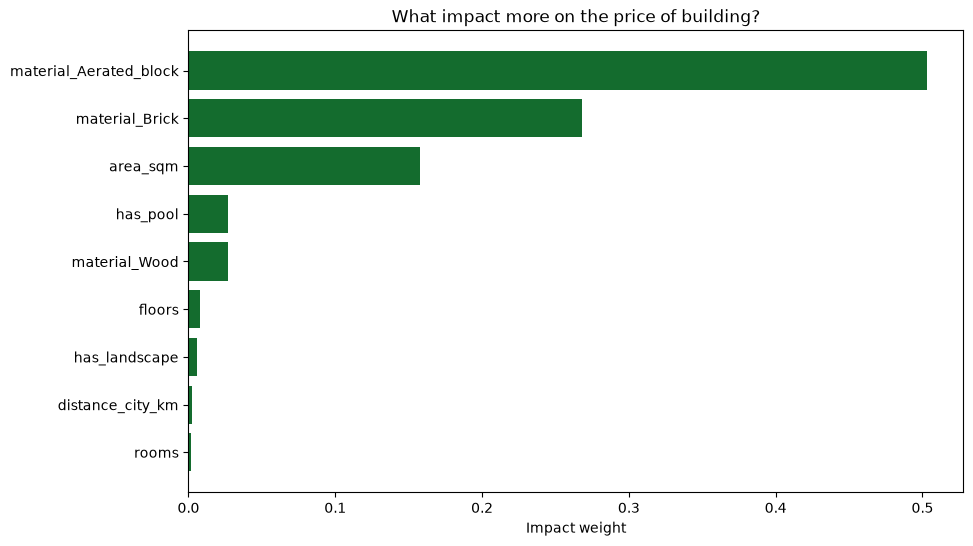

In [6]:
import numpy as np
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"R2 Score: {r2:.4f} (1.0 - Perf)")
print(f"Avarage error (MAE): ${mae:,.0f}")

plt.figure(figsize=(10, 6))
importances = model.feature_importances_
cols = X.columns
sorted_idx = np.argsort(importances)

plt.barh(cols[sorted_idx], importances[sorted_idx], color='#146c2e')
plt.title("What impact more on the price of building?")
plt.xlabel("Impact weight")
plt.show()

In [7]:
import joblib
import os

# Створюємо папку
os.makedirs('../models', exist_ok=True)

# Зберігаємо ПОРЯДОК колонок (їх безпечно зберігати через joblib, це просто текст)
joblib.dump(list(X_train.columns), '../models/model_features.pkl')

# 🚀 НОВИЙ СПОСІБ ЗБЕРЕЖЕННЯ МОДЕЛІ (Кросплатформний)
model.save_model('../models/house_pricer_xgb.json')

print("✅ Модель успішно збережено у форматі JSON!")

✅ Модель успішно збережено у форматі JSON!
